In [73]:
import lsdb
import nested_pandas as npd
import time

print(npd.__version__, lsdb.__version__)

0.7.3.dev23+ga57123467 0.11.1


# DG1. Multi-modal data access and throughput
Metric: Retrieval of multi-modal data using a 60 arcsecond cone search is comparable (within 50% wall clock time) to a current tabular-only LSDB catalog query.

Rationale: Demonstrate that the infrastructure can provide a single point of access to multi-modal data that will unlock new statistical analyses and machine learning models.

(<Figure size 1000x500 with 2 Axes>,
 <WCSAxes: title={'center': 'Catalog pixel map - mmu_legacysurvey_dr10_south_21_x_mmu_desi_edr_sv3'}>)

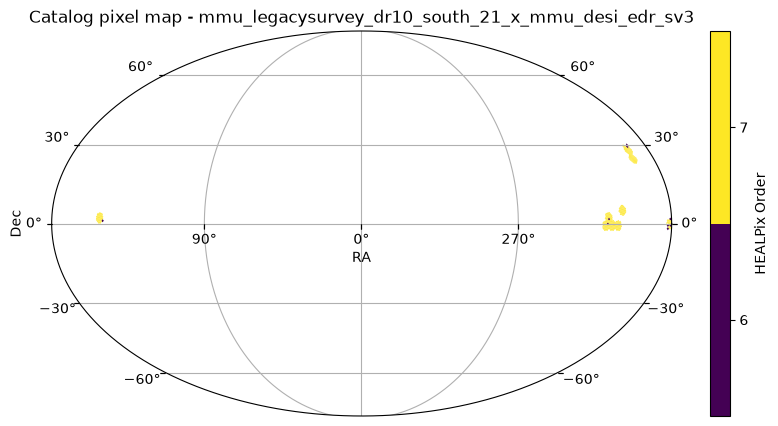

In [77]:
lsdb.open_catalog("/sdf/data/rubin/cosmicdata/lsdb/genesis/milestone2").plot_pixels()

## Performance Testing a 60 arcsec Cone

> **Note**: With the milestone2 dataset, a 60 arcsec cone will only return a few rows. So a performance comparison will show that the tabular only data performance is dominated by LSDB/dask overhead, whereas the multimodal performance has a more significant I/O operation to measure as it is significantly more data per row.

In [90]:
cone = lsdb.ConeSearch(ra=216.0, dec=0.5, radius_arcsec=60.0)
#cone = lsdb.ConeSearch(ra=216.0, dec=2, radius_arcsec=6000.0)
base_columns = ["ra_mmu_legacysurvey_dr10_south_21", "dec_mmu_legacysurvey_dr10_south_21",
                "ra_mmu_desi_edr_sv3", "dec_mmu_desi_edr_sv3", "_dist_arcsec"]

tab_only_cat = lsdb.open_catalog("/sdf/data/rubin/cosmicdata/lsdb/genesis/milestone2",
                                columns=base_columns, search_filter=cone)

multimodal_cat = lsdb.open_catalog("/sdf/data/rubin/cosmicdata/lsdb/genesis/milestone2",
                                search_filter=cone)

In [94]:
def time_catalog(catalog, deep=True, **compute_kwargs):
    """Time catalog.compute() and normalize by the size of the returned frame.

    Returns (result, elapsed_s, s_per_mb).
    """
    start = time.perf_counter()
    result = catalog.compute(**compute_kwargs)
    elapsed = time.perf_counter() - start

    mb = result.memory_usage(deep=deep).sum() / 1024**2
    s_per_mb = mb/elapsed if mb > 0 else float("nan")
    return result, elapsed, s_per_mb, mb

In [115]:
result, elapsed, s_per_mb, mb_total = time_catalog(tab_only_cat)
print(f"{elapsed:.2f} s total, {s_per_mb:.4f} MB/s ({len(result)} rows) {mb_total} MB total")

Building task graph...


Computing Catalog:   0%|          | 0/4 [00:00<?, ?it/s]

0.03 s total, 0.0115 MB/s (8 rows) 0.0003662109375 MB total


In [118]:
result, elapsed, s_per_mb, mb_total = time_catalog(multimodal_cat)
print(f"{elapsed:.2f} s total, {s_per_mb:.4f} MB/s ({len(result)} rows) {mb_total} MB total")

Building task graph...


Computing Catalog:   0%|          | 0/4 [00:00<?, ?it/s]

0.83 s total, 5.0434 MB/s (8 rows) 4.168731689453125 MB total


## Performance testing with roughly equivalent resulting data volume

>**Note**: Even this case isn't apples to apples, as the large cone introduces many partitions. This translates to many tasks in Dask, which each have their own overhead to access.

In [112]:
# Use a larger cone for tabular only
large_cone = lsdb.ConeSearch(ra=216.0, dec=2, radius_arcsec=60000.0)
tab_only_cat_large = lsdb.open_catalog("/sdf/data/rubin/cosmicdata/lsdb/genesis/milestone2",
                                columns=base_columns, search_filter=large_cone)

In [114]:
result, elapsed, s_per_mb, mb_total = time_catalog(tab_only_cat_large)
print(f"{elapsed:.2f} s total, {s_per_mb:.4f} MB/s ({len(result)} rows) {mb_total} MB total")

Building task graph...


Computing Catalog:   0%|          | 0/562 [00:00<?, ?it/s]

2.26 s total, 1.8712 MB/s (90967 rows) 4.229942321777344 MB total


In [119]:
result, elapsed, s_per_mb, mb_total = time_catalog(multimodal_cat)
print(f"{elapsed:.2f} s total, {s_per_mb:.4f} MB/s ({len(result)} rows) {mb_total} MB total")

Building task graph...


Computing Catalog:   0%|          | 0/4 [00:00<?, ?it/s]

0.90 s total, 4.6475 MB/s (8 rows) 4.168731689453125 MB total
